In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from rich import print, pretty
pretty.install()
data = pd.read_csv("../../SyntheticData_Training.csv")
data = data.iloc[:, 1:] # remove id column
target = data.columns[-1] # save target column


count    2686.00000
mean       21.12338
std        13.05725
min         5.90000
25%        10.52500
50%        16.90000
75%        28.67500
max        61.80000
Name: agecalc_adm, dtype: float64


['5-17', '39-50', '28-39', '17-28', '50-61']
Categories (5, object): ['5-17' < '17-28' < '28-39' < '39-50' < '50-61']

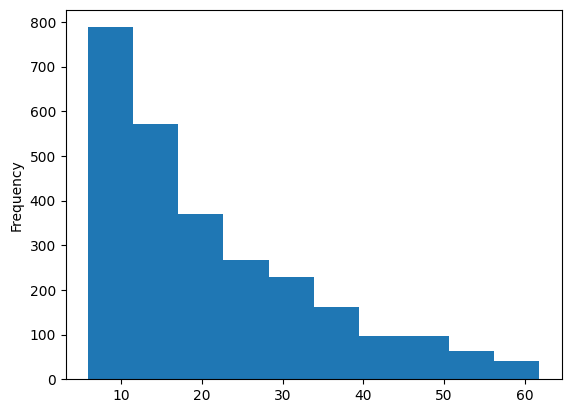

In [2]:
data["agecalc_adm"].plot(kind='hist')
display(data["agecalc_adm"].describe())
# convert age to categorical feature with 5 groups
num_bins = 5
bin_edges = np.linspace(data["agecalc_adm"].min(), data["agecalc_adm"].max(), num_bins + 1)
labels = [f"{int(bin_edges[i])}-{int(bin_edges[i+1])}" for i in range(len(bin_edges)-1)]
# age_categorical_engineered
data["agecat_engr"] = pd.cut(data["agecalc_adm"], bins=bin_edges, labels=labels, include_lowest=True)
data["agecat_engr"].unique()

In [3]:
# select relevant categorical
cols_df = pd.read_csv("../../column_decisions.csv")
relevant_categorical_columns = cols_df[(cols_df['Relevancy']=='RELEVANT') & (cols_df["Variable Type"].str.startswith('Categorical'))]['Variable Name'].tolist()
# some string manipulation required
for i, col in enumerate(relevant_categorical_columns):
    if col not in data.columns:
        relevant_categorical_columns[i] = col.replace('adm_', 'adm___')

df = data[relevant_categorical_columns].copy()
df["agecat_engr"] = data["agecat_engr"]

In [4]:
# fill in missing values using 'most frequent' 
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
print(f"Missing values before SimpleImputer: {df.isna().sum().sum()}")

imp = SimpleImputer(strategy="most_frequent")
df = pd.DataFrame(imp.fit_transform(df), columns=df.columns)
print(f"Missing values after SimpleImputer: {df.isna().sum().sum()}")

Missing values before SimpleImputer: 146

Missing values after SimpleImputer: 0

# Unsupervised Learning
## 1. Clustering with KModes

/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


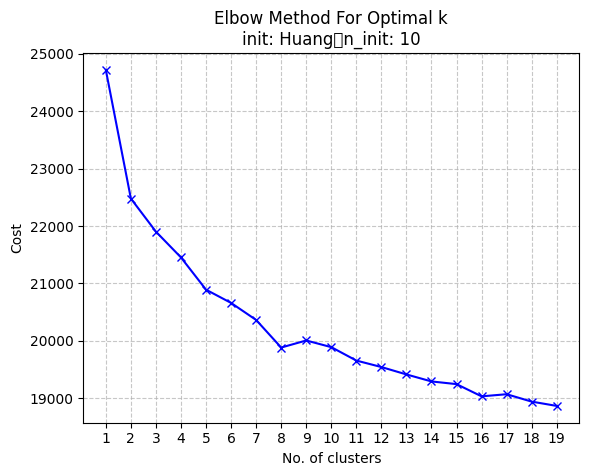

/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


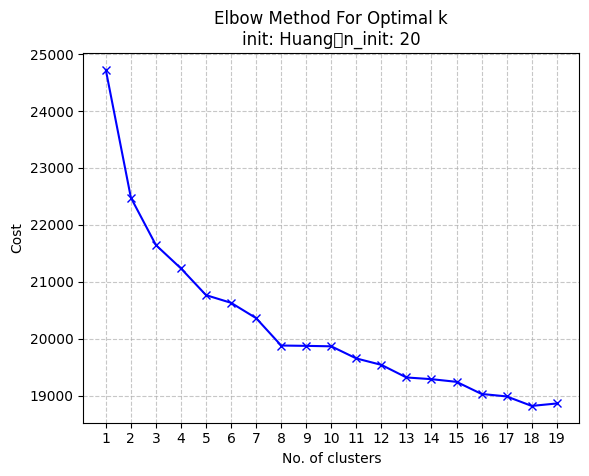

/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


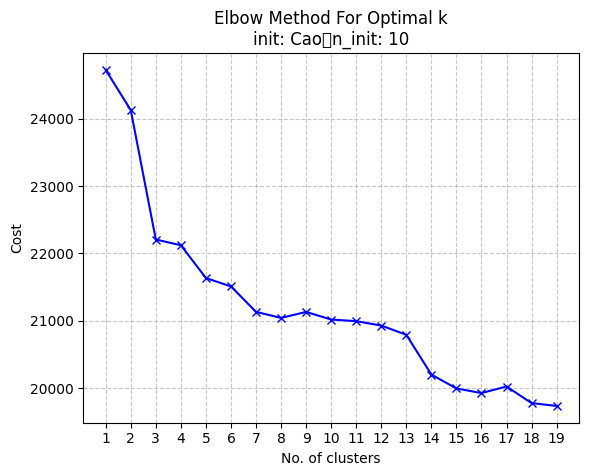

/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


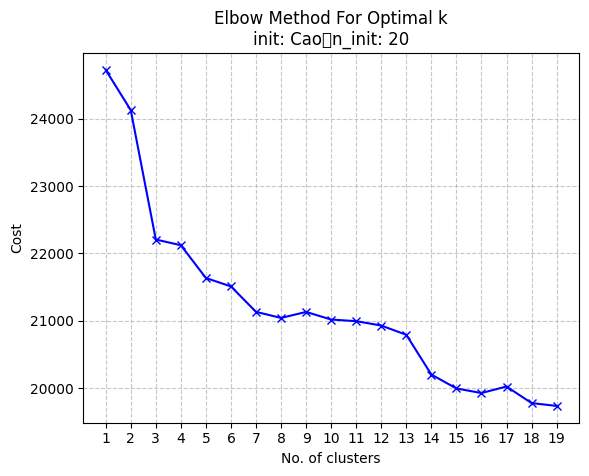

/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


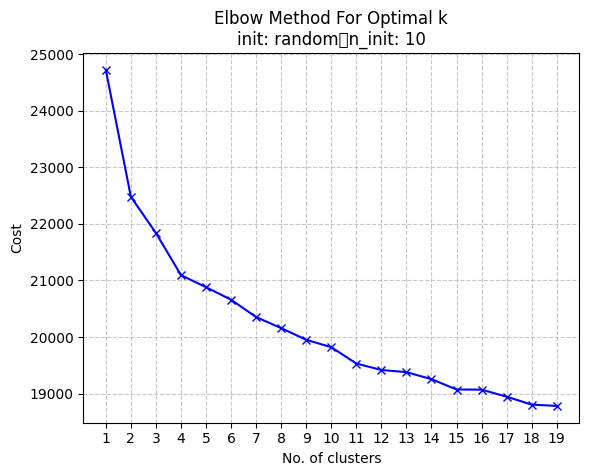

/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


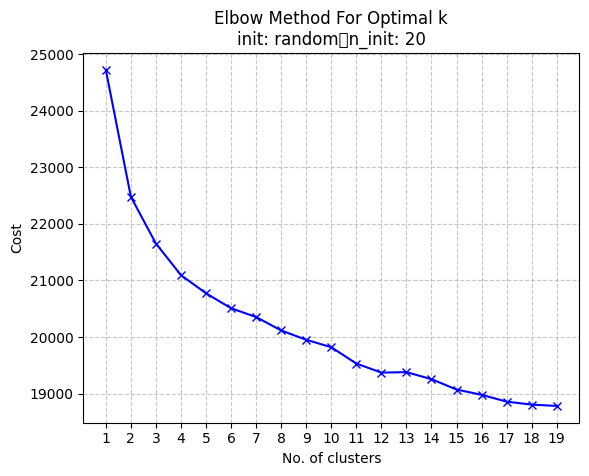

In [8]:
from kmodes.kmodes import KModes

K = range(1,20)
inits = ['Huang', 'Cao', 'random']
n_inits = [10, 20]

for init in inits:
    for n_init in n_inits:
        cost = []
        for num_clusters in K:
            km = KModes (n_clusters=num_clusters, 
                            init=init,
                            n_init=n_init,
                            verbose=0,
                            random_state=88)
            km.fit_predict(df)
            cost.append(km.cost_)

        plt.plot(K, cost, 'bx-')
        plt.xlabel('No. of clusters')
        plt.ylabel('Cost')
        plt.xticks(K)
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.title(f'Elbow Method For Optimal k\ninit: {init}\tn_init: {n_init}')
        # plt.legend()
        plt.show()

## Observations:

* `inits = "Huang"` -> 8 clusters
* `inits = "Cao"` -> 3 clusters

### `inits = "Cao"` -> 3 clusters

In [13]:
from kmodes.kmodes import KModes
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
# create the clusters
kmodes = KModes(n_clusters=3, init='Cao', random_state=88)
clusters = kmodes.fit_predict(df)

# evaluate the clustering
y = data[target]
ari = adjusted_rand_score(y, clusters)
nmi = normalized_mutual_info_score(y, clusters)

print(f"Adjusted Rand Index: {ari}")
print(f"Normalized Mutual Information: {nmi}")

Adjusted Rand Index: 0.00453011574683961

Normalized Mutual Information: 0.003232470117959371

In [16]:
from kmodes.kmodes import KModes
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
# create the clusters
dictionary_results_ari = {}
dictionary_results_nmi = {}
for k in range(1,20):
    kmodes = KModes(n_clusters=k, init='Huang', random_state=88)
    clusters = kmodes.fit_predict(df)

    # evaluate the clustering
    y = data[target]
    ari = adjusted_rand_score(y, clusters)
    nmi = normalized_mutual_info_score(y, clusters)
    dictionary_results_ari[k] = ari
    dictionary_results_nmi[k] = nmi